In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

# this is copied from /admin-where-is-M1

In [3]:
prefix = '/mnt/staging/' # or
mouse='cm219'

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"


h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'



# 1. spontaneous running

```

% day4,5,6,7,8,10 runBCD 10min
% day11 runCD
% day 10 runB BUG
% 11 runB BUG
% 10 runE BUG
```

In [44]:
f1 = list(set(glob.glob(step_2_root+"*219/[1-4]/H_*[B-K]*.mat")) )
# f2 = list(set(glob.glob(step_2_root+"*219/4/H_*[B-H]*.mat")) )
# f3 = list(set(glob.glob(step_2_root+"*219/4/H_*[H]*.mat")) )

file_spont = f1
print(len(file_spont))
file_spont


32


['/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/1/H_runF_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/4/H_runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/4/H_runG_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/2/H_runH_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/3/H_runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/1/H_runI_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/1/H_runH_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/3/H_runK_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/2/H_runG_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/2/H_runF_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm219/3/H_runG_stim_1.mat',
 '/mnt/sta

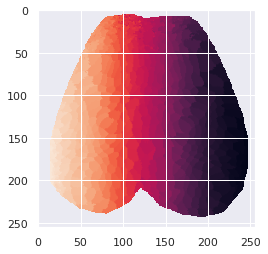

In [45]:
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse)
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [35]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

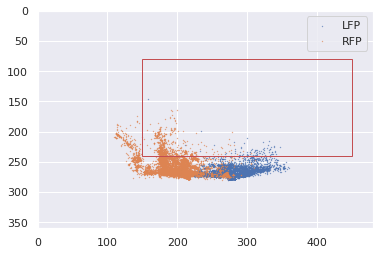

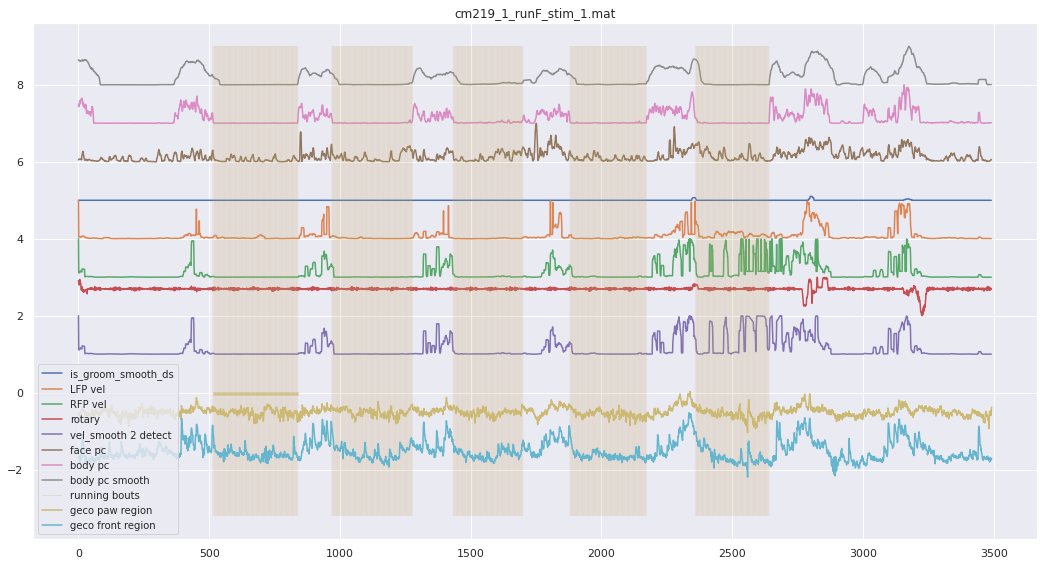

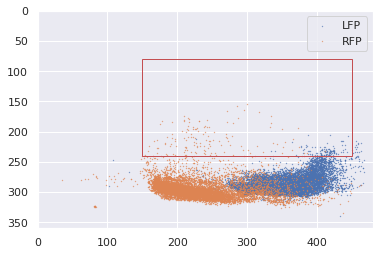

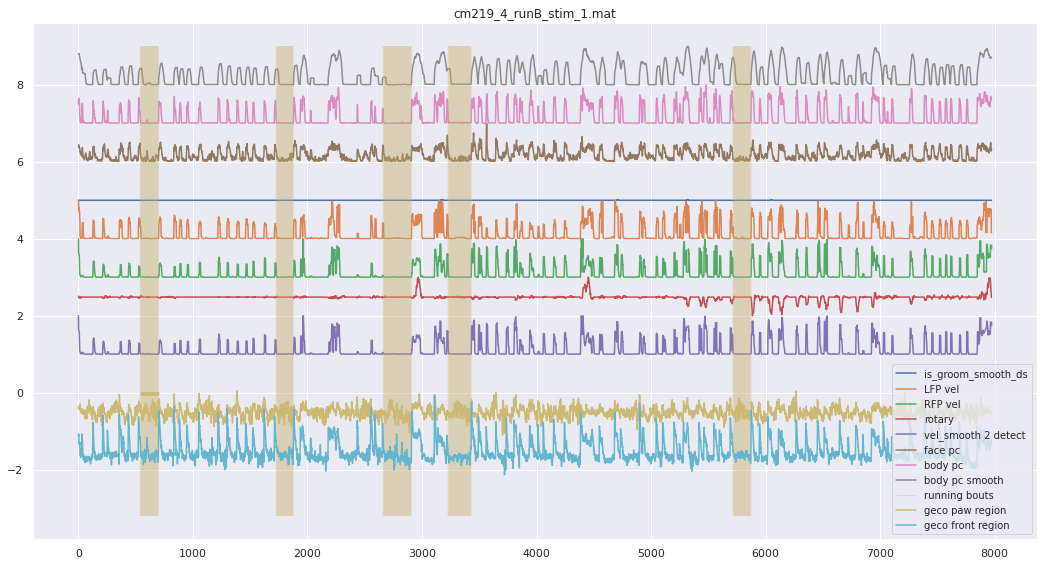

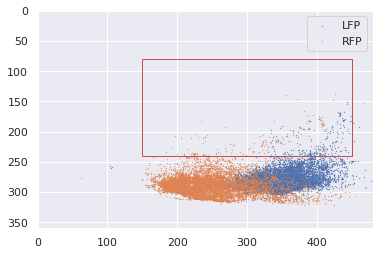

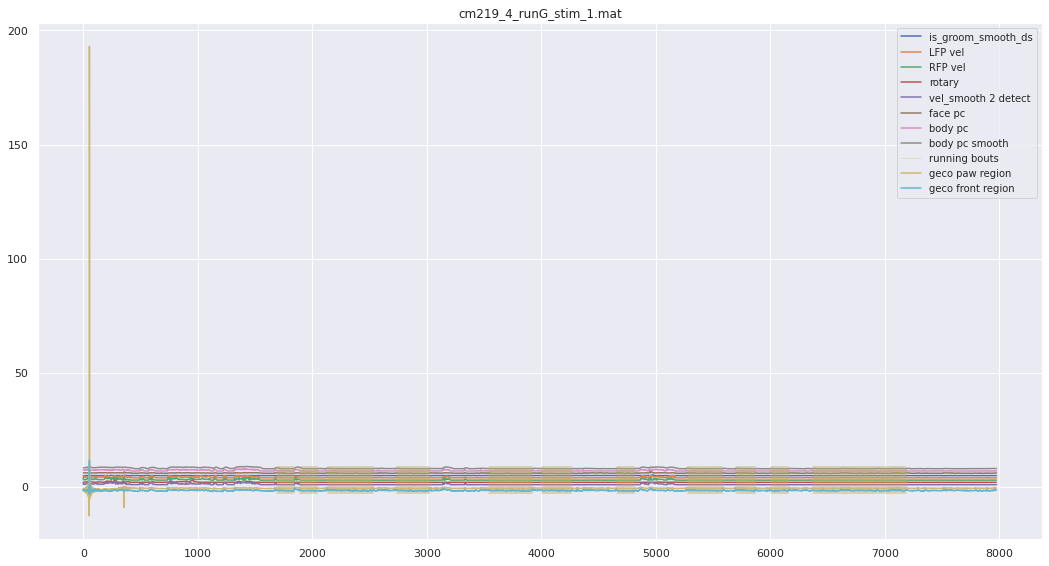

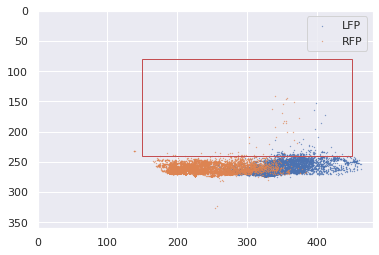

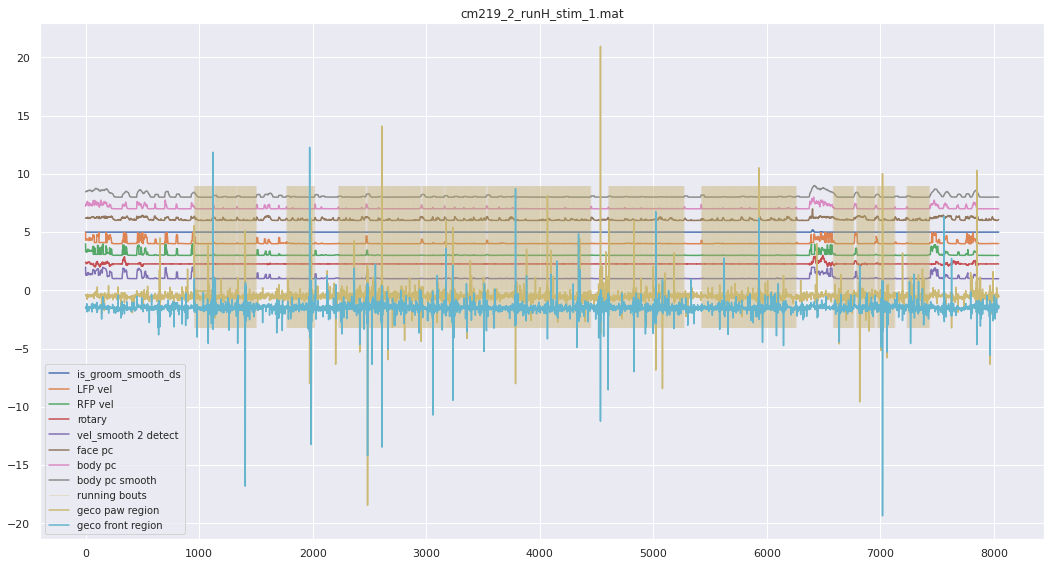

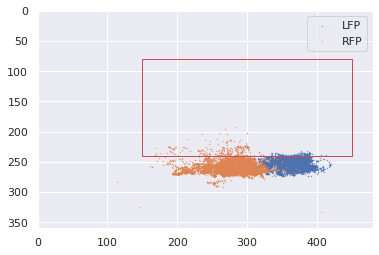

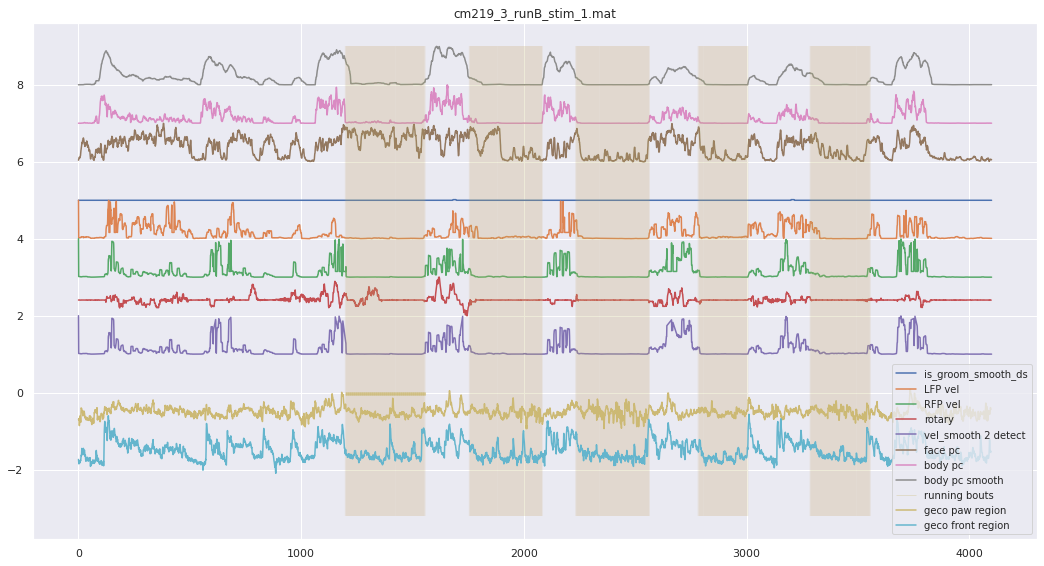

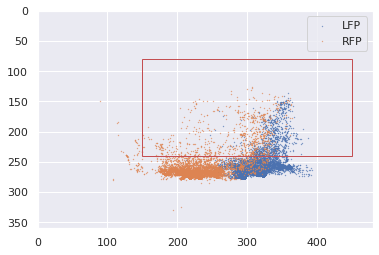

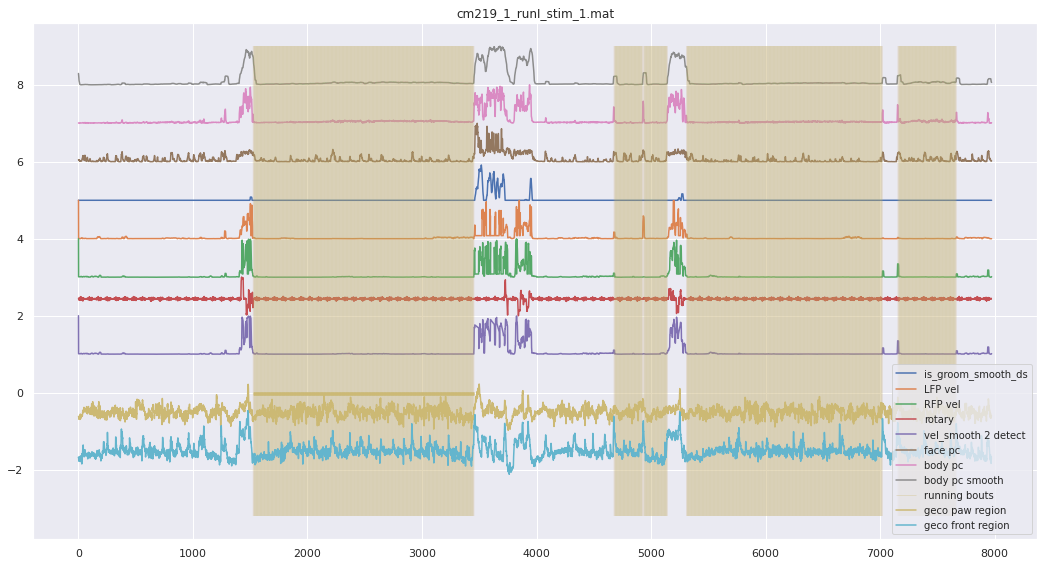

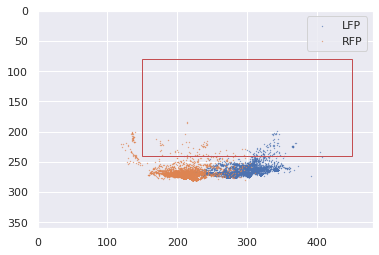

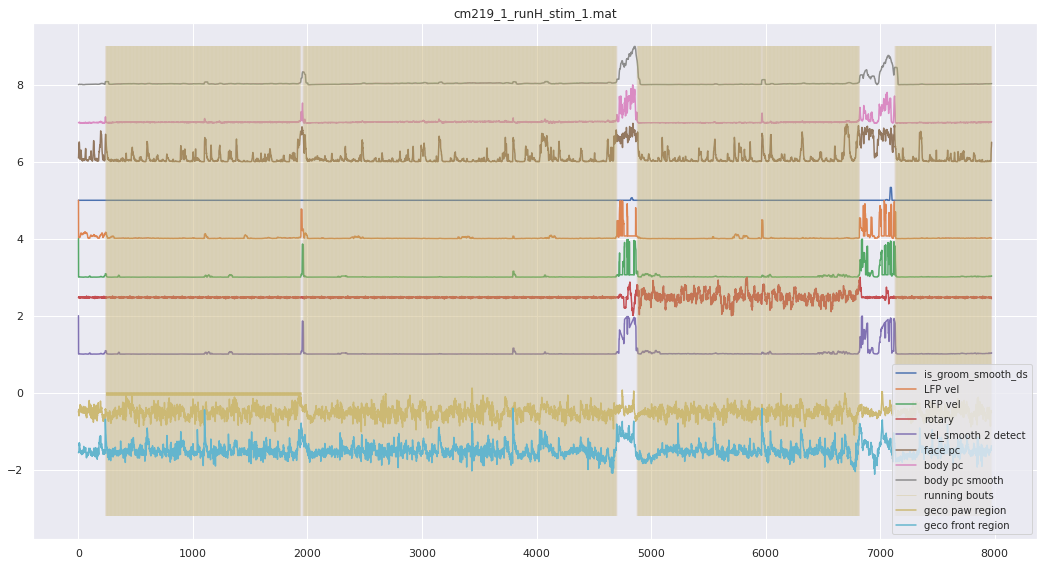

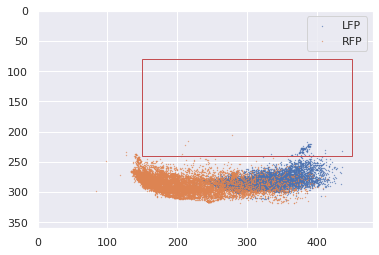

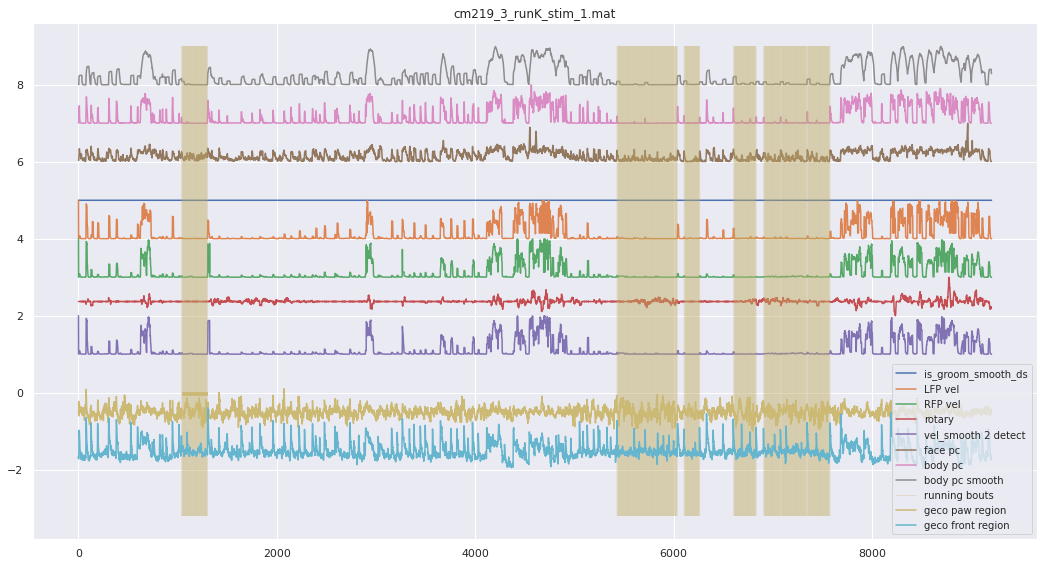

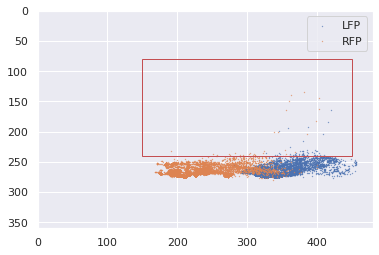

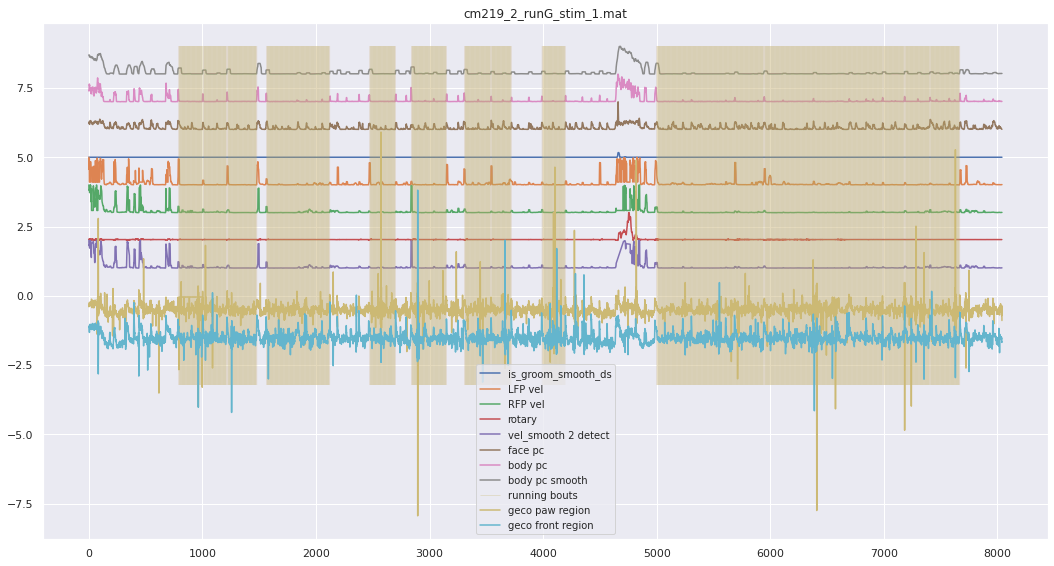

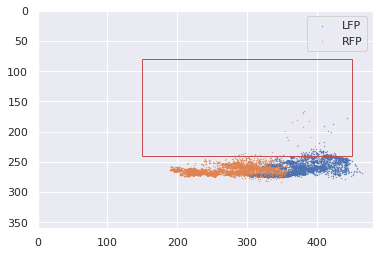

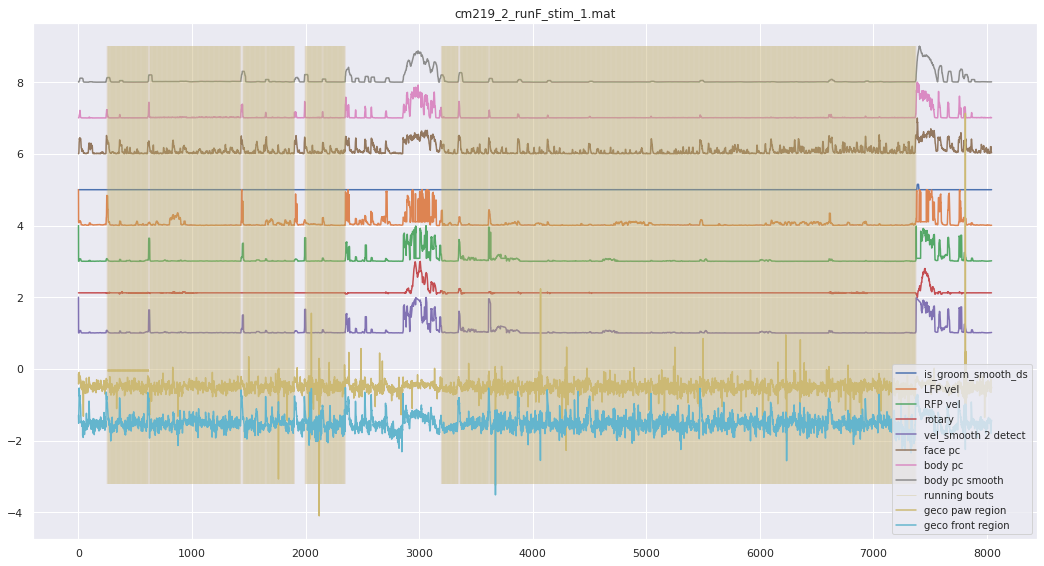

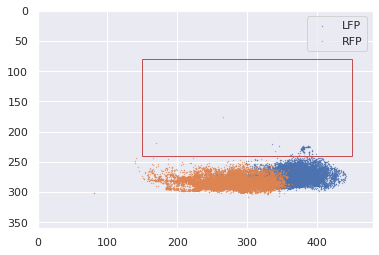

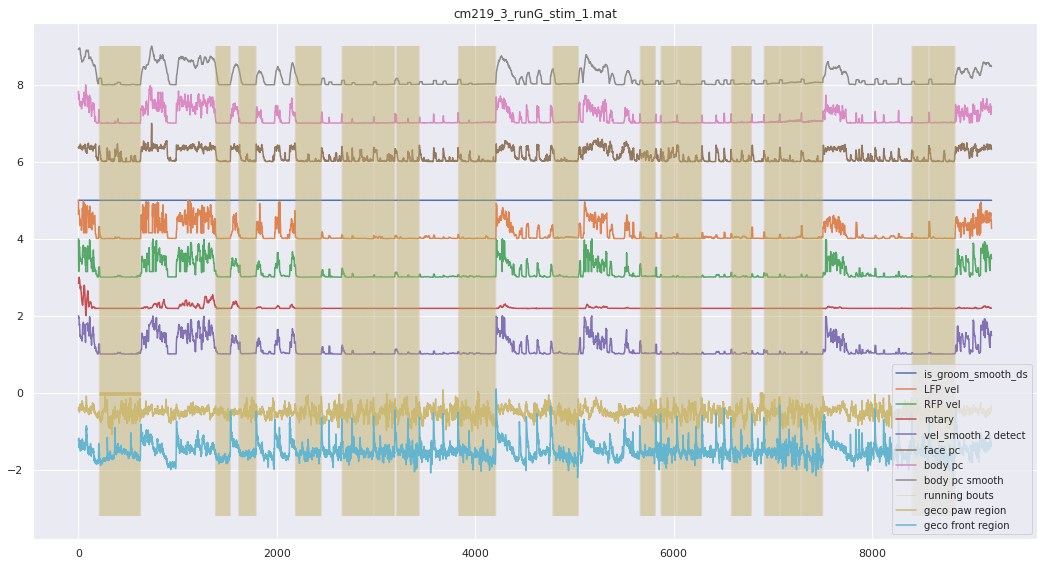

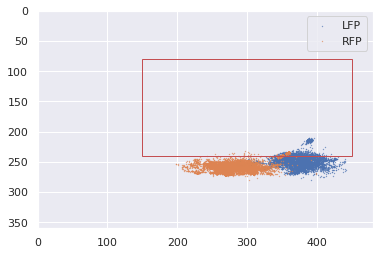

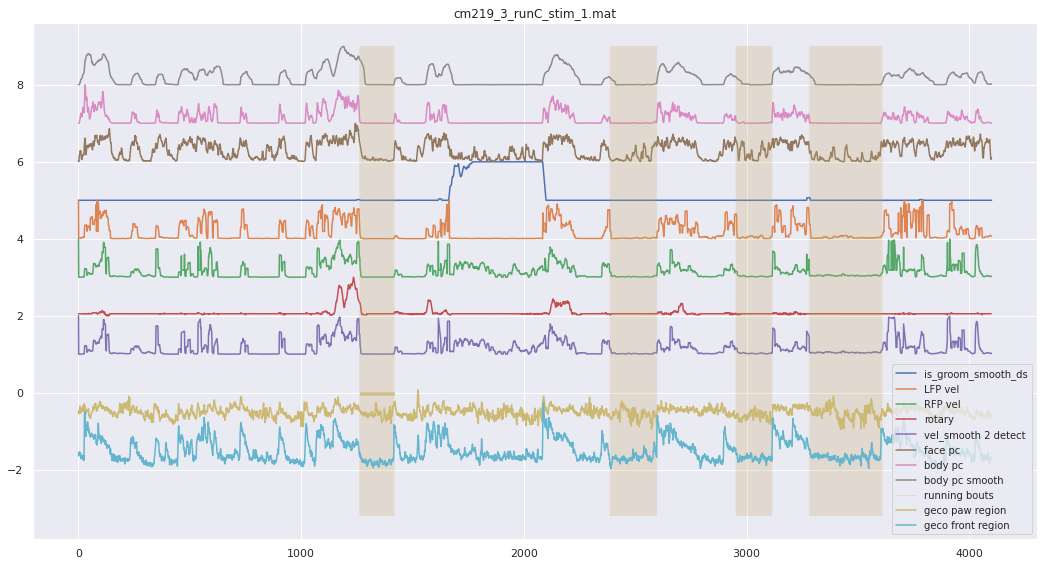

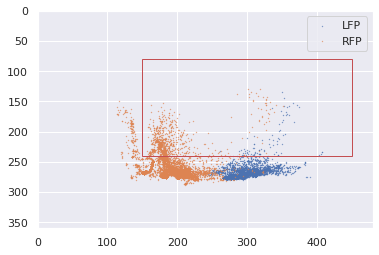

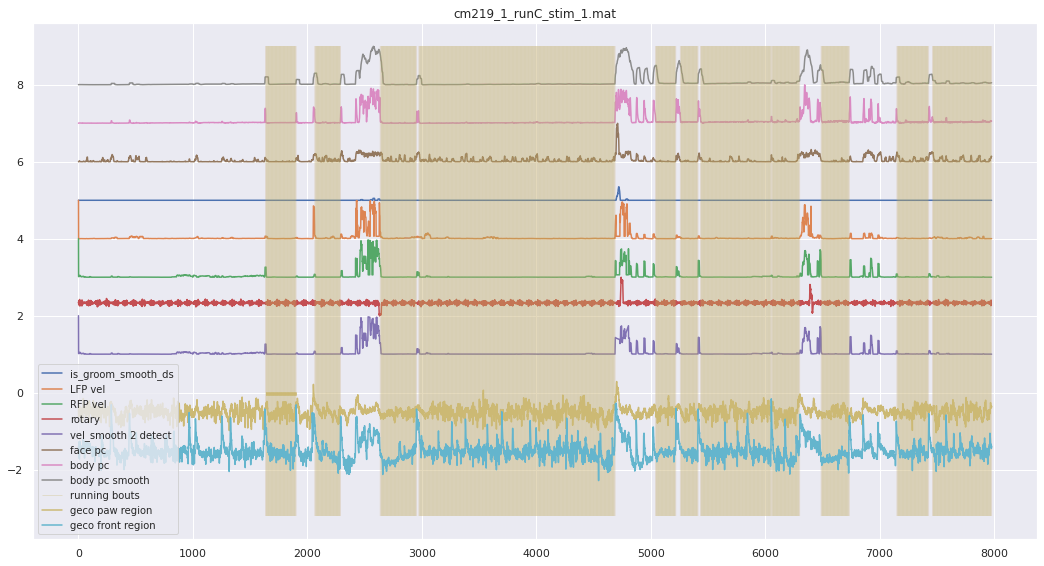

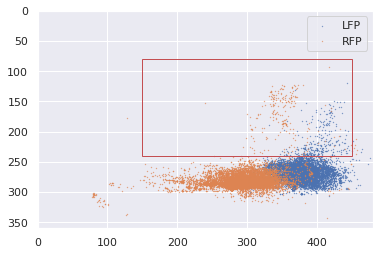

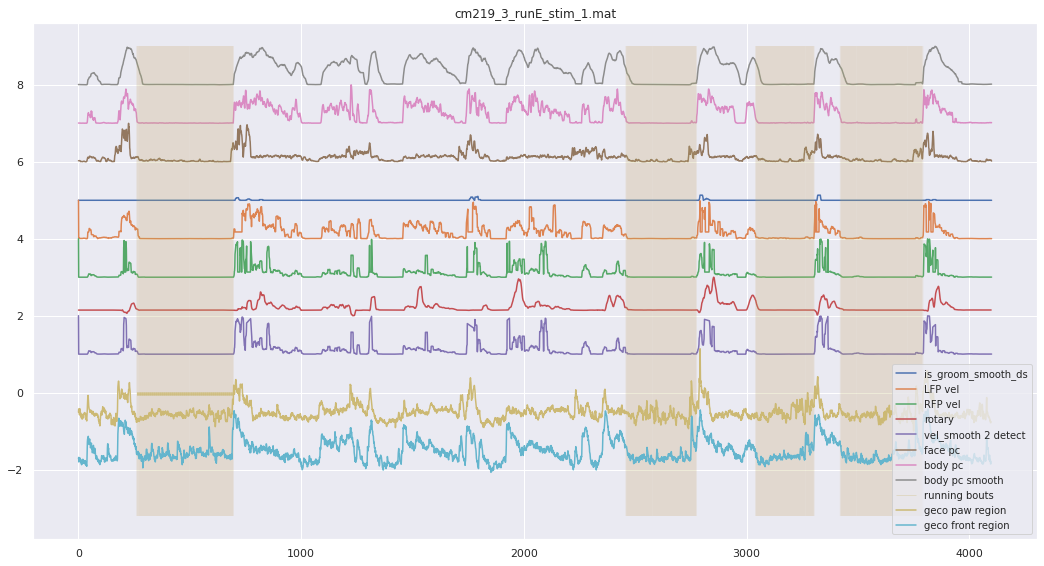

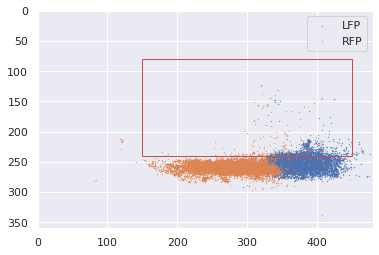

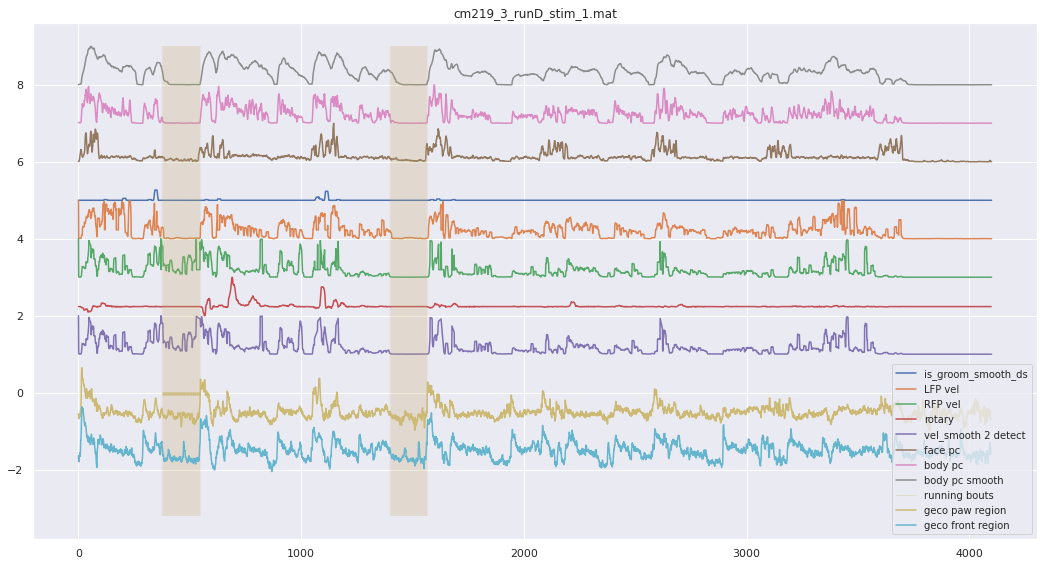

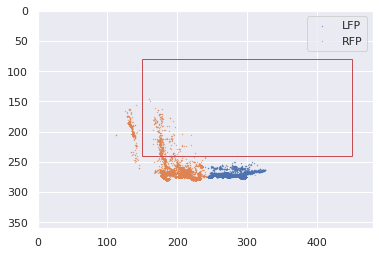

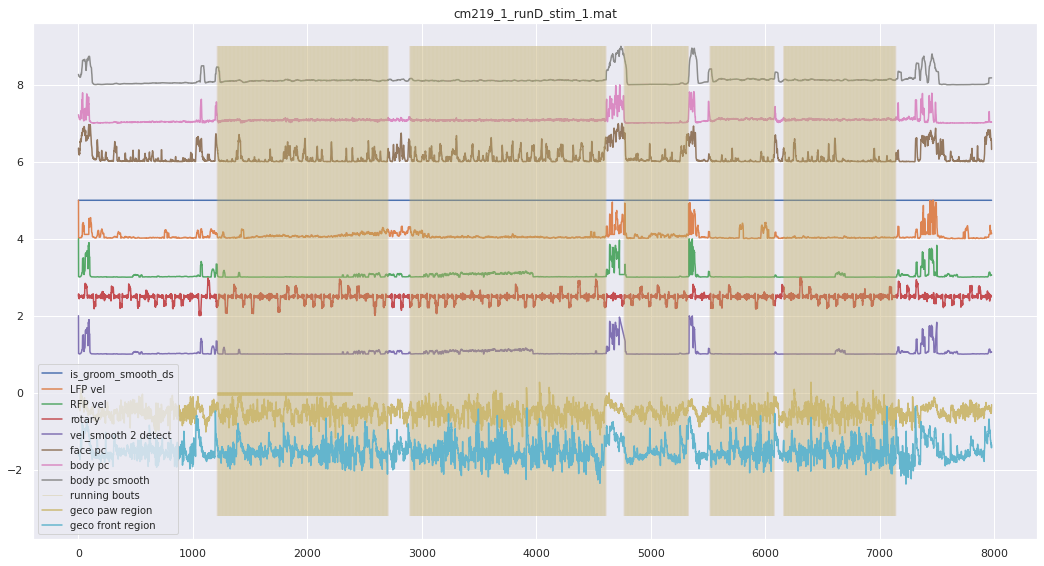

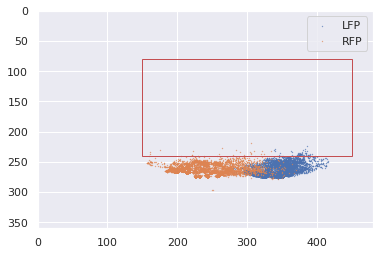

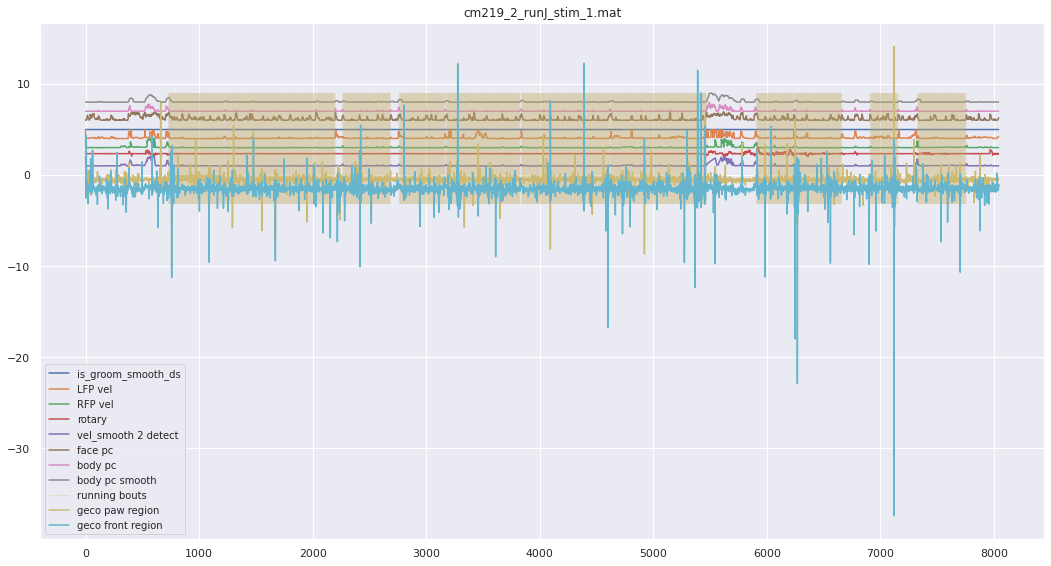

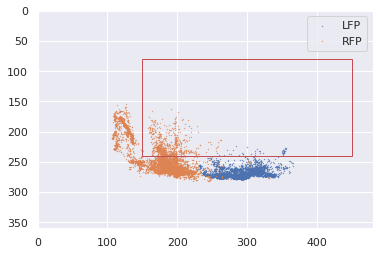

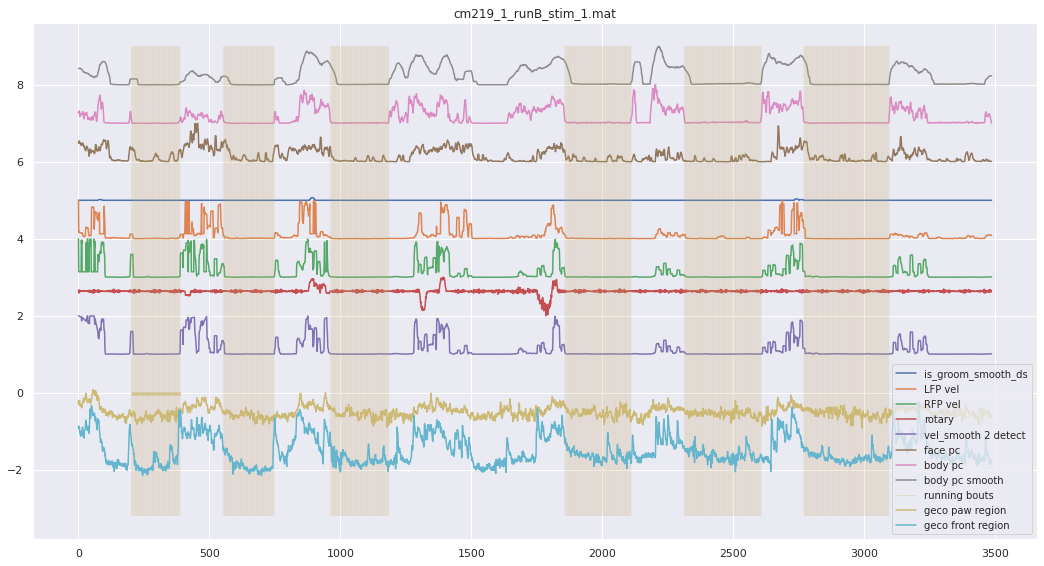

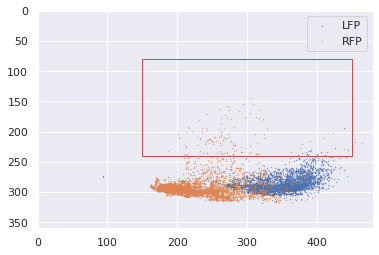

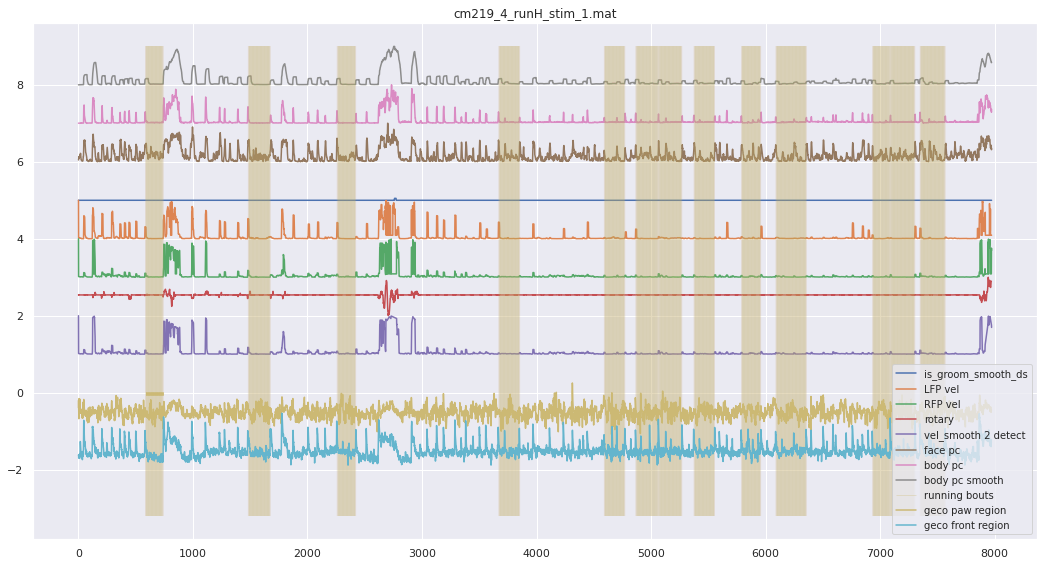

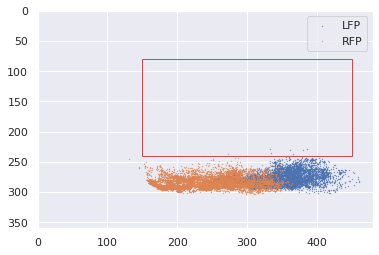

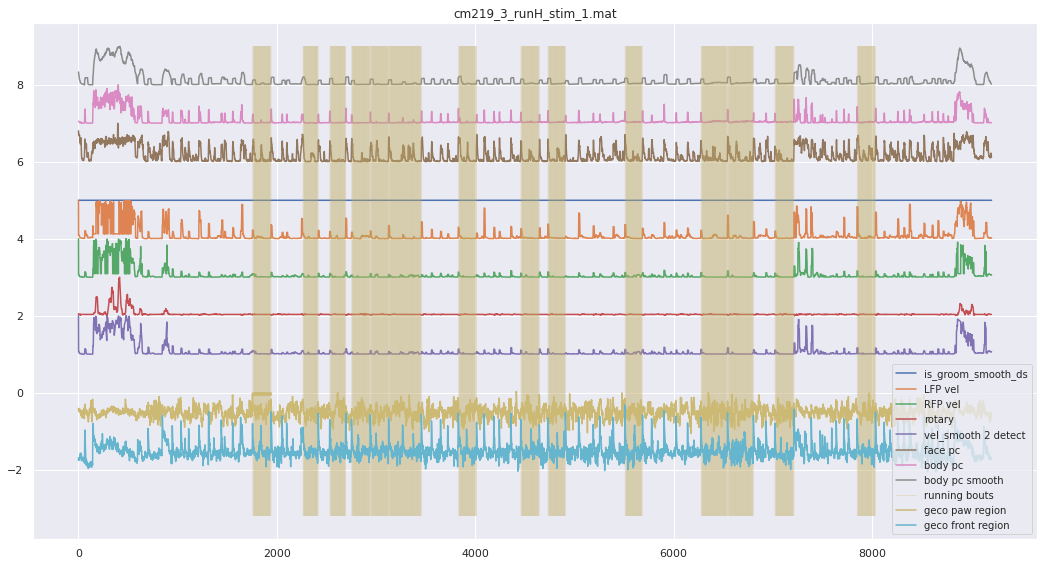

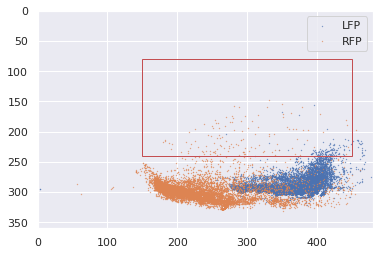

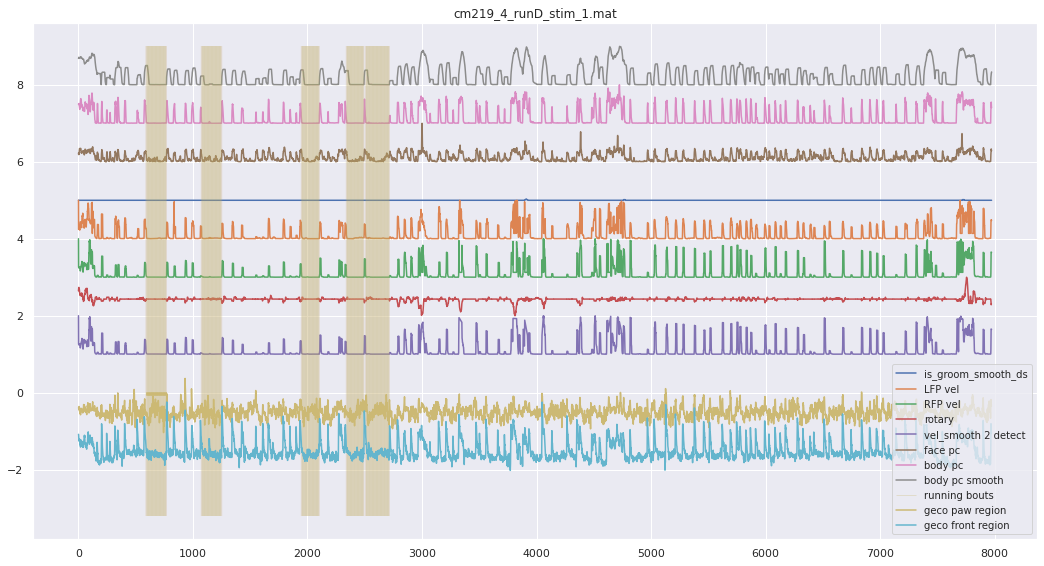

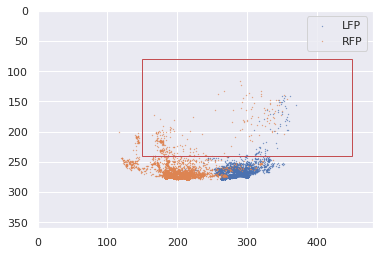

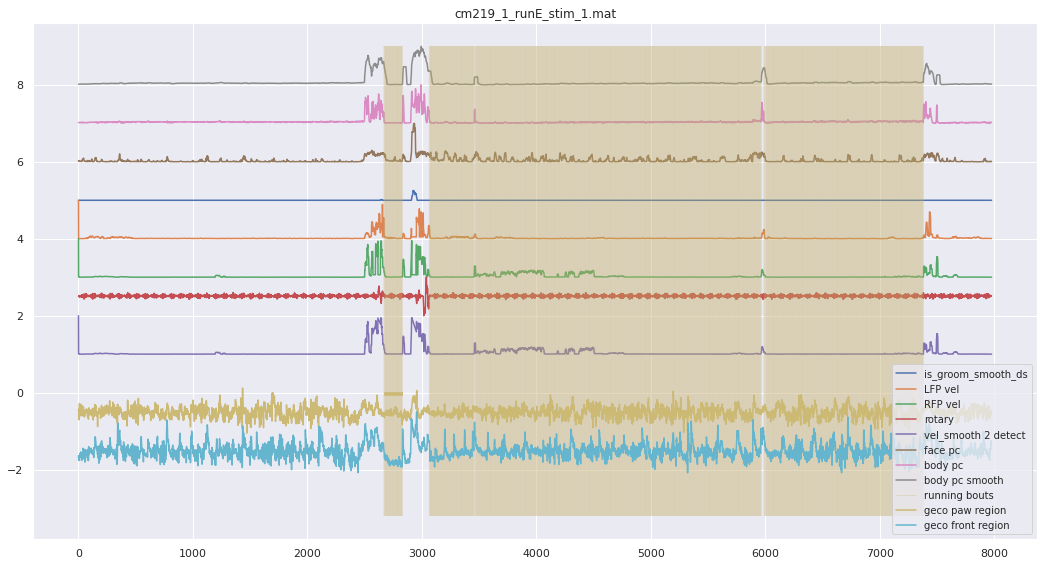

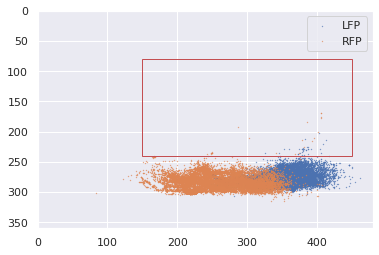

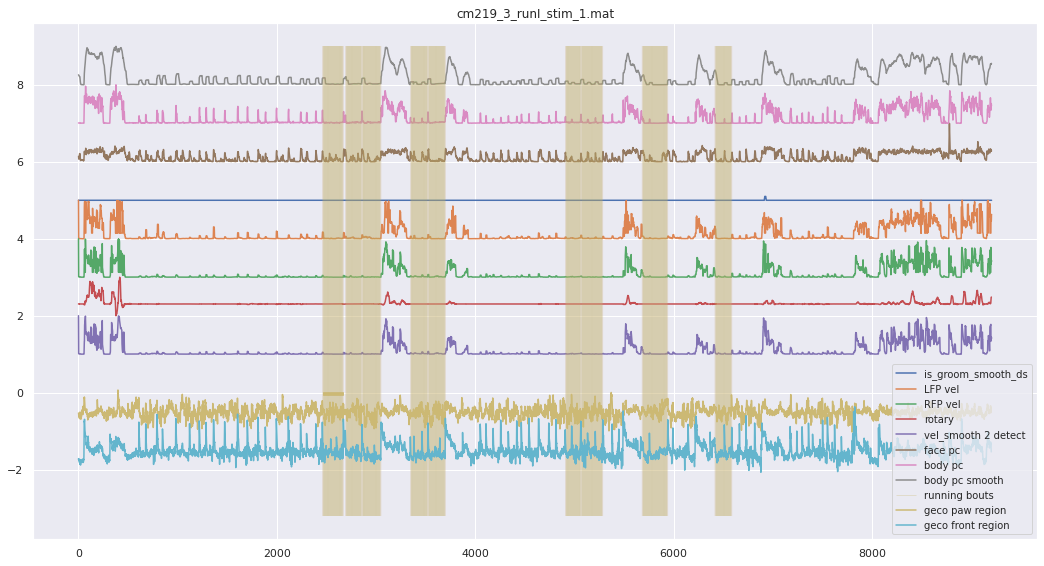

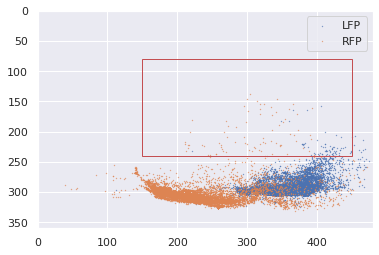

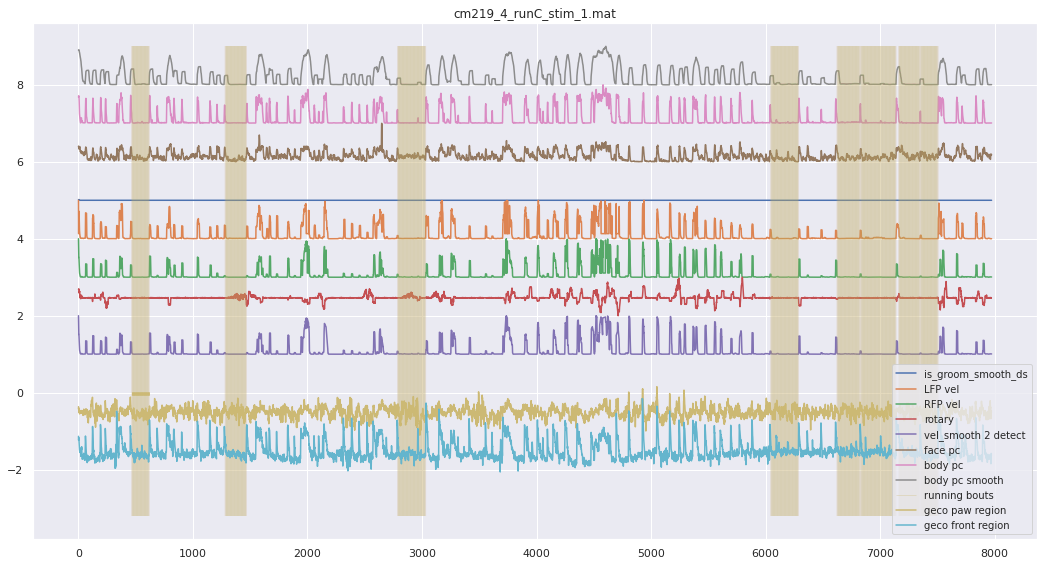

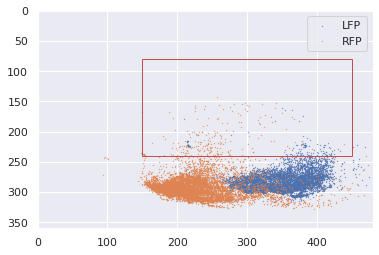

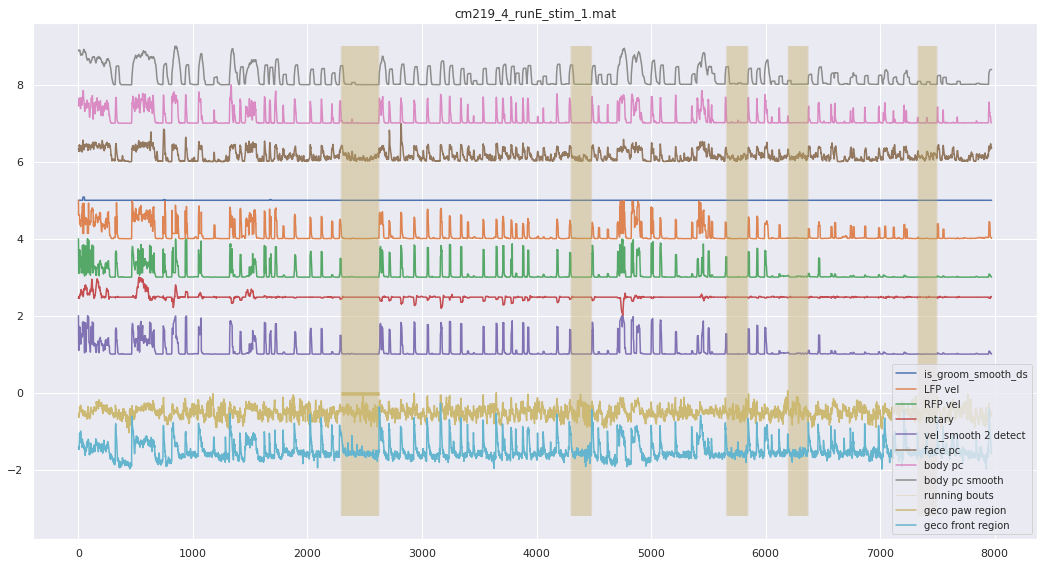

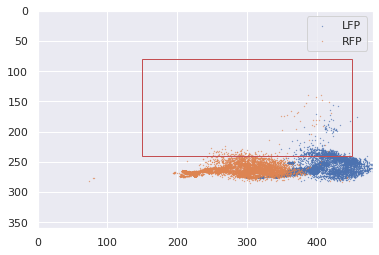

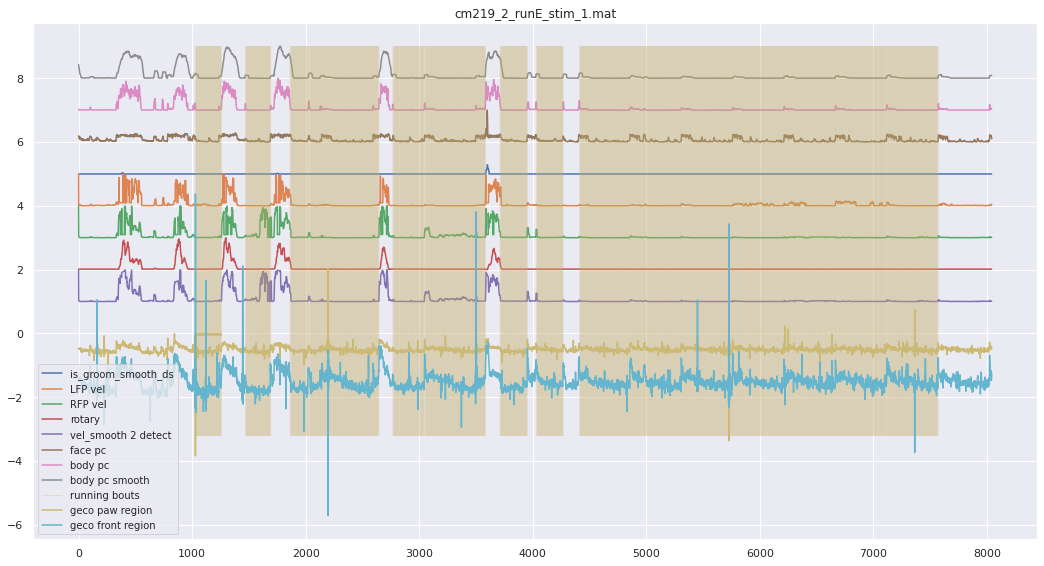

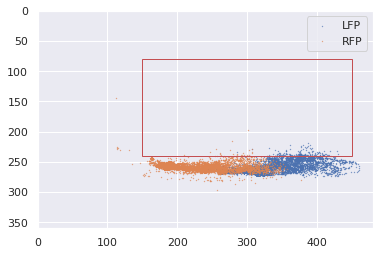

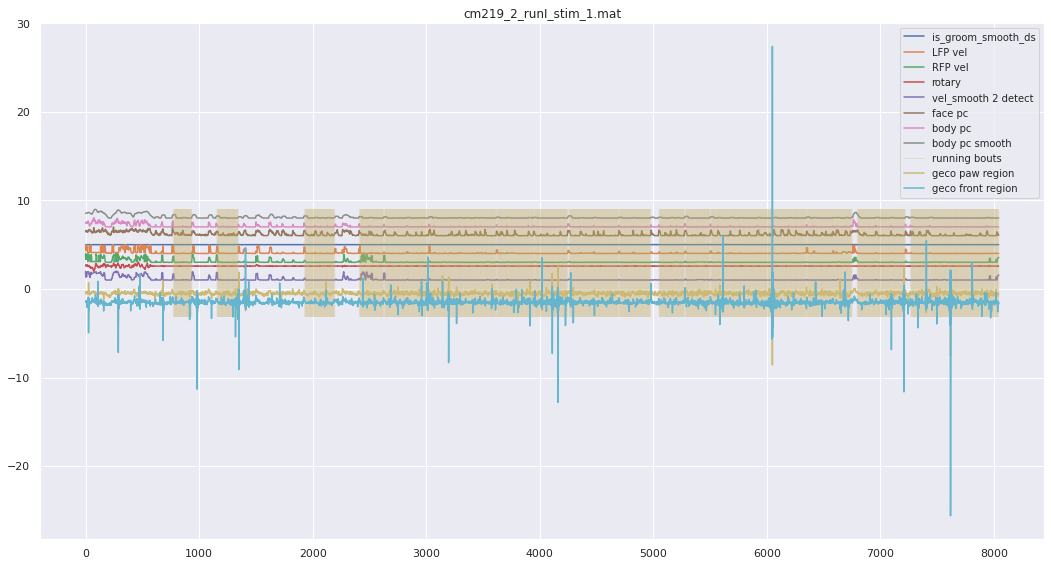

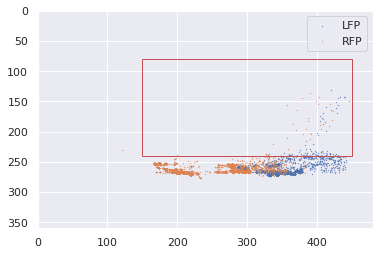

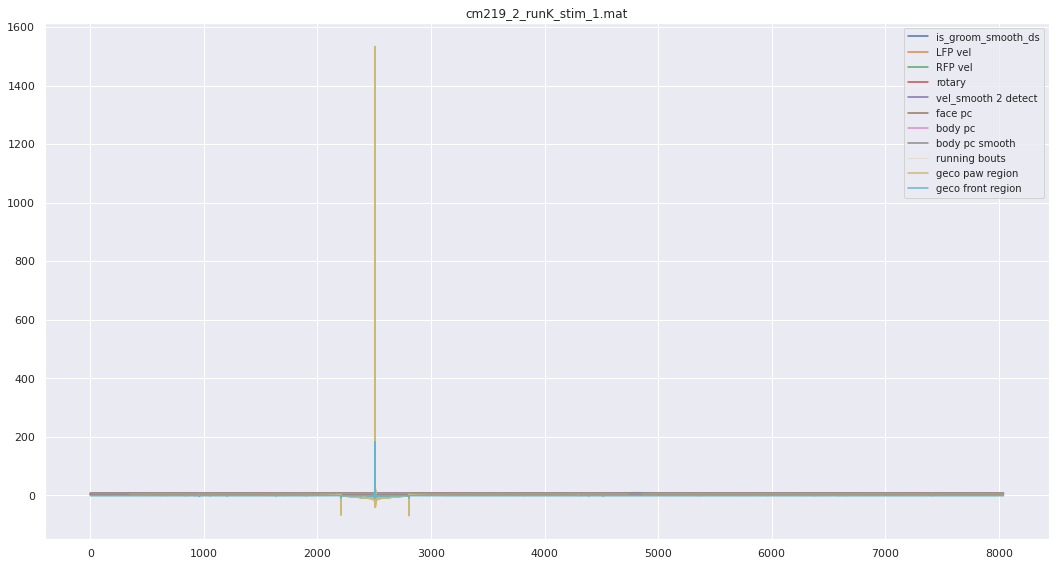

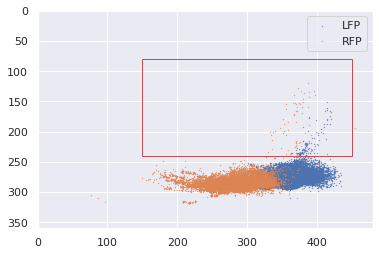

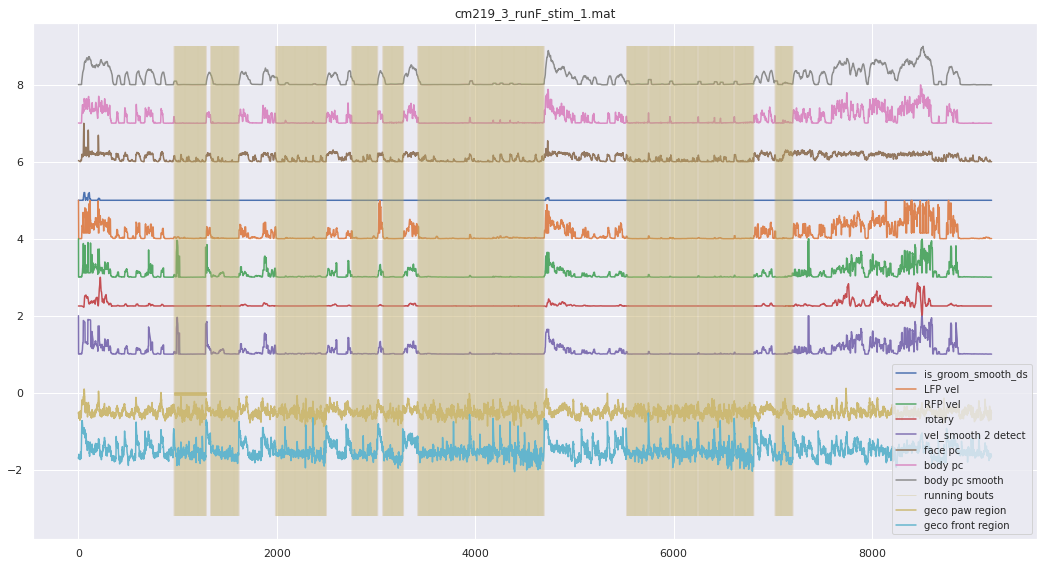

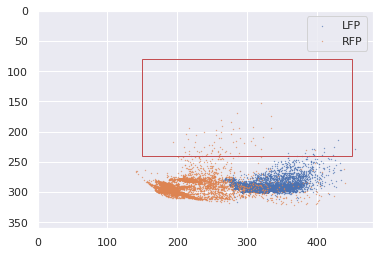

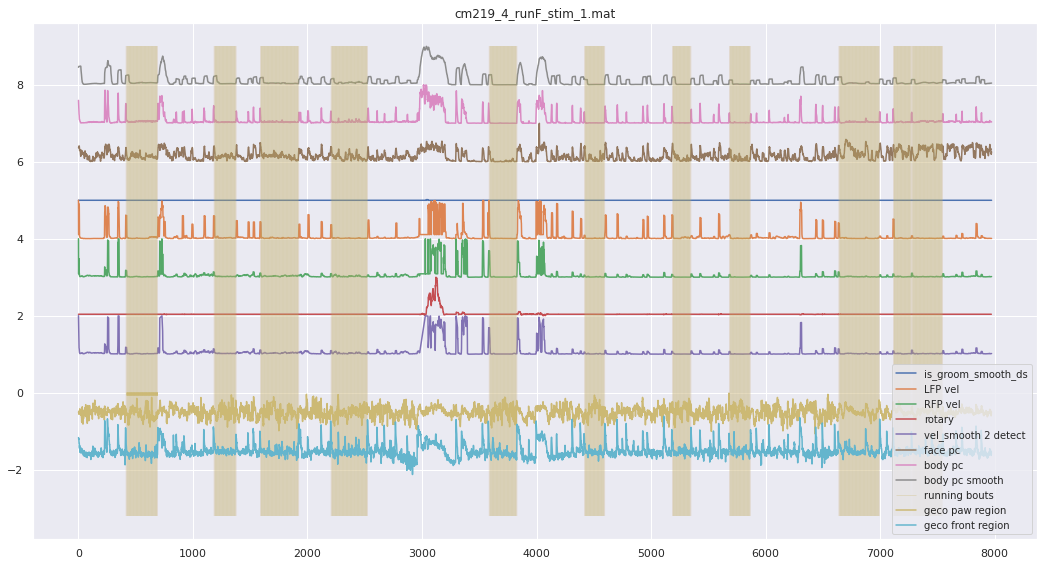

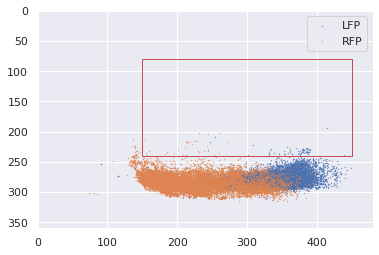

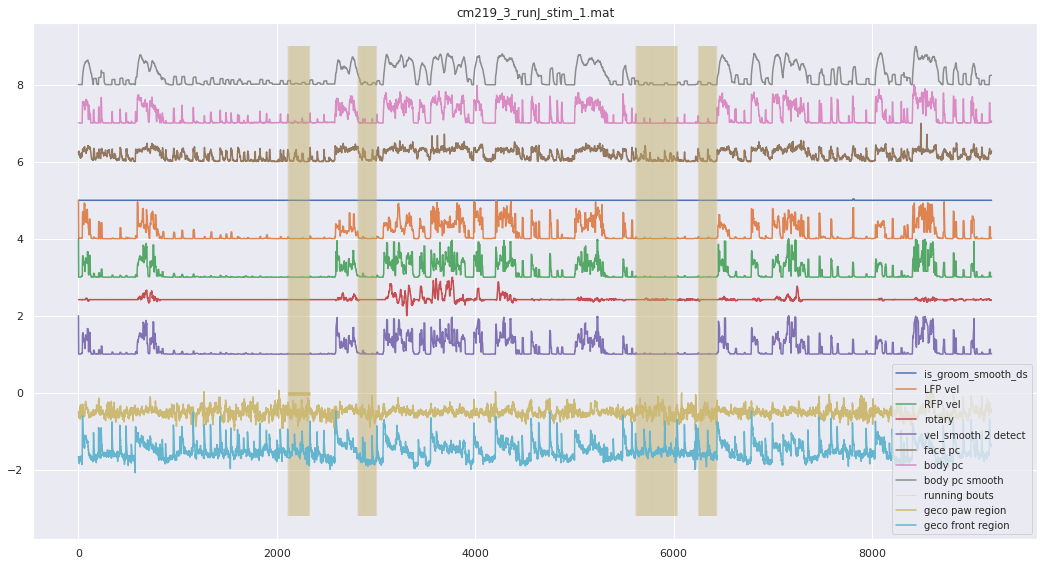

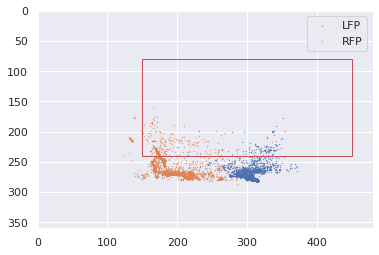

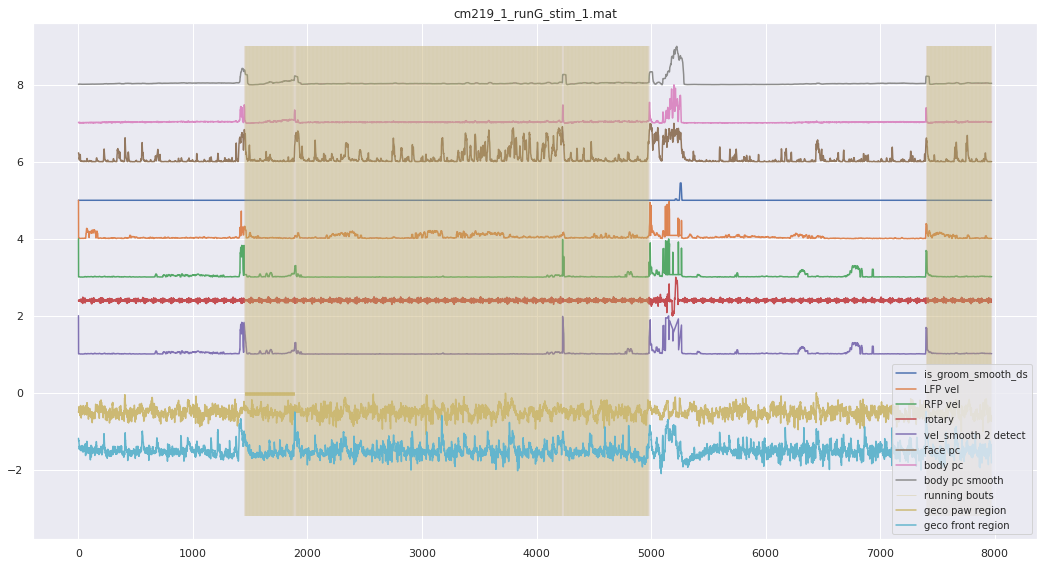

In [46]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 100
T_POST = 400
T=T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = np.empty((num_regions,T,0))
M_gcamp = np.empty((num_regions,T,0))
M_chbt = np.empty((num_regions,T,0))

M_day_label =  np.empty((0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_rotf = np.empty((T,0))
M_rotf_smooth = np.empty((T,0))
M_ind = np.empty((0))
M_ind_stop = np.empty((0))
M_is_groom = np.empty((T,0))
M_body_pc_smooth = np.empty((T,0))

M_mirrorRFP_vel = np.empty((T,0))
M_mirrorRFP_vel_norm = np.empty((T,0))
M_mirrorLFP_vel = np.empty((T,0))
M_mirrorLFP_vel_norm = np.empty((T,0))
M_mirrorRHP_vel = np.empty((T,0))
M_mirrorRHP_vel_norm = np.empty((T,0))
M_mirrorLHP_vel = np.empty((T,0))
M_mirrorLHP_vel_norm = np.empty((T,0))


data_joint=pd.DataFrame()
for i_file,fname in enumerate(file_spont): 
    f = h5py.File(fname,'r')
    ################################### identity 
    split1=fname.split('/H_')
    run_name = split1[1]
    run = run_name[:4]
    day=split1[0].split(mouse+'/')[1]
    mouse_day = mouse+'_'+day

    try:
        with h5py.File(fname,'r') as f_H: 
            H = np.array(f_H['H']).transpose() #(36,11975)       
            H = H[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            total_tpt=H.shape[-1]
            H_gcamp = np.array(f_H['H_gcamp']).transpose() #(36,11975)       
            H_gcamp = H_gcamp[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            H_chbt = np.array(f_H['H_chbt']).transpose() #(36,11975)       
            H_chbt = H_chbt[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

            m=f_H['m']
            a=np.array(m['DAQ_ds'])
            rot = np.rad2deg(np.unwrap(a[:,-1]))
            rot = np.diff(rot)
            z = np.abs(stats.zscore(rot))
            threshold = 3
            outlier_ind = np.squeeze(np.where(z > 3))
            rot[outlier_ind]=np.nan
            rot_smooth = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).mean().fillna(0))))
            rot_smooth = rot_smooth[500:-506]
            rot_2_detect = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).std().rolling(20).mean().fillna(0))))
            rot_2_detect = rot_2_detect[500:-506]
            
    except:
        print('missing',mouse,day,'H_'+run+'_stim_1.mat')
        continue

        
    # try:    

    f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

    for i_bpt,bpt in enumerate(['LFP','RFP']):#make sure RFP comes out last
        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel_smooth = pd.DataFrame(vel).rolling(40).std()
        vel = pd.DataFrame(vel).rolling(40).std()
        tocut = vel.shape[0]%4
        if tocut ==0:
            vel = np.mean(vel.values.reshape((-1,4)),axis=1)
            vel_smooth = np.mean(vel_smooth.values.reshape((-1,4)),axis=1)
        else:
            vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)  
            vel_smooth = np.mean(vel_smooth[:-tocut].values.reshape((-1,4)),axis=1) 

        paws_vel_df[bpt] = stats.zscore(vel[500:-505])
        vel_ds = paws_vel_df[bpt].copy()
        vel_ds[vel_ds>3]=np.nan;vel_ds[0]=3;
        paws_vel_df[bpt]=vel_ds
        paws_vel_df[bpt] = paws_vel_df[bpt].fillna(0)
        paws_vel_df[bpt]=np.array(paws_vel_df[bpt].interpolate())

        vel_smooth = stats.zscore(vel_smooth[500:-505])
        vel_smooth[vel_smooth>3]=np.nan;vel_smooth[0]=3;

        vel_smooth=np.array(pd.DataFrame(vel_smooth).interpolate())


    LFP_vel = stats.zscore(np.array(paws_vel_df['LFP']))
    RFP_vel = stats.zscore(np.array(paws_vel_df['RFP']))
    vel_smooth = stats.zscore(vel_smooth)

    # is_groom plot # (480,360)
    import matplotlib.patches as patches

    x_top_left=80
    x_botton_right=240
    y_top_left=150
    y_botton_right=450

    out_h = int(x_botton_right - x_top_left)
    out_w = int(y_botton_right - y_top_left)
    y = x_top_left
    x = y_top_left

    fig,ax = plt.subplots(1)
    plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
    plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
    rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
    plt.ylim([0,360])
    plt.xlim([0,480])
    plt.legend()
    ax.add_patch(rect)
    plt.gca().invert_yaxis()      


    is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
    is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
    is_groom = np.logical_and(is_groom_LFP,is_groom_RFP)
    is_groom_smooth = is_groom.rolling(60).mean()
    if tocut ==0:
        is_groom_smooth_ds = np.mean(is_groom_smooth.values.reshape((-1,4)),axis=1)
    else:
        is_groom_smooth_ds = np.mean(is_groom_smooth[:-tocut].values.reshape((-1,4)),axis=1) #(11980,)
    is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    if tocut ==0:
        new_df = new_df.groupby(np.arange(new_df.shape[0])//4, axis=0).mean()
    else:
        new_df = new_df[:-tocut].groupby(np.arange(new_df[:-tocut].shape[0])//4, axis=0).mean()

    new_df = new_df.iloc[500:-505]


    # except:
    #     # there's no DLC for day1-3
    #     print('DLC paws missing ',mouse_day+'_'+run)   
    #     continue



    f_name_dlc = glob.glob(mirror_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df_2 = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

    for i_bpt,bpt in enumerate(['LFP','RFP','LHP','RHP']):
        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df_2[bpt]['x'].values.flatten(), new_df_2[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel).rolling(40).std()
        tocut = vel.shape[0]%4
        if tocut ==0:
            vel = np.mean(vel.values.reshape((-1,4)),axis=1)
        else:
            vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)   
        paws_vel_df[bpt] = vel[500:-505]

    mirrorLFP_vel = np.array(paws_vel_df['LFP'])
    mirrorRFP_vel = np.array(paws_vel_df['RFP'])
    mirrorLHP_vel = np.array(paws_vel_df['LHP'])
    mirrorRHP_vel = np.array(paws_vel_df['RHP'])

    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)

    if tocut ==0:
        new_df_2 = new_df_2.groupby(np.arange(new_df_2.shape[0])//4, axis=0).mean()
    else:
        new_df_2 = new_df_2[:-tocut].groupby(np.arange(new_df_2[:-tocut].shape[0])//4, axis=0).mean()
    new_df_2 = new_df_2.iloc[500:-505]

    data_pot = pd.concat([new_df,new_df_2],
                     keys=['front','mirror'],names=['column_level'],axis=1)


    with(h5py.File(pjoin(step_3_root,
                             mouse,day,run+'_cam1_pc.mat'),'r')) as f_b:
        motionS = f_b['motionS']# this is the HDF5 reference
        motion_pc = {key: [] for key in list(motionS.keys())} 
        motion_pc_2detect = {key: [] for key in list(motionS.keys())} 
        for key in list(motionS.keys()):

            motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
            # (200,T)
            ss=motion_pc[key].shape
            tocut = ss[1]%4
            if tocut ==0:
                motion_pc[key] = np.mean(motion_pc[key].values.reshape((ss[0],int(ss[1]/4),4)),axis=2)
            else:
                motion_pc[key] = np.mean(motion_pc[key].iloc[:,:-tocut].values.reshape((ss[0],-1,4)),axis=2)

            motion_pc_2detect[key] = pd.DataFrame(motion_pc[key]).rolling(window=30,axis=1).std()                
            motion_pc[key] = pd.DataFrame(motion_pc[key]).rolling(window=5,axis=1).std()
            motion_pc_2detect[key]=motion_pc_2detect[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            motion_pc[key]=motion_pc[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = stats.zscore(np.array(face_pc))
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = stats.zscore(np.array(body_pc))
    body_pc_smooth = motion_pc_2detect['body'].iloc[:200,:].mean(axis=0)
    body_pc_smooth = stats.zscore(np.array(body_pc_smooth))    

        
    ################### plotting stuffs + ***[start_stop_ind]*** 
    
    running_ind = np.squeeze(normalize(body_pc) < 0.15)

    start_stop_ind = pd.DataFrame(start_stop(np.squeeze(running_ind),trigger_val = True))
    start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
    start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
    start_stop_ind = start_stop_ind.fillna(1000)
    
    # start_stop_ind = start_stop_ind[start_stop_ind['distance_difference']>10]
    start_stop_ind = start_stop_ind[start_stop_ind['duration']>150]
    start_stop_ind = start_stop_ind[start_stop_ind[0]>T_PRE+1]
    start_stop_ind = start_stop_ind[start_stop_ind[0]<len(face_pc)-(T_PRE+T_POST)]
    

    
    
    # here is_groom means if both forepaws in ROI regions
    is_groom_start_stop = start_stop(np.squeeze(is_groom_smooth_ds>0.1),trigger_val = True)
    
    temp = []
    for i in range(len(start_stop_ind)):
        x1 = start_stop_ind.iloc[i,0];x2 = start_stop_ind.iloc[i,1];
        temp.append(any(max(x1,lower) <= min(x2,upper) for (lower, upper) in list(is_groom_start_stop)))
    start_stop_ind['is_in_groom']=temp
    start_stop_ind = start_stop_ind[start_stop_ind['is_in_groom']==False]

    
    try:
        plt.figure(figsize=(18,9.5))
        plt.plot(is_groom_smooth_ds+5,label='is_groom_smooth_ds')
        plt.plot(normalize(LFP_vel)+4,label='LFP vel')
        plt.plot(normalize(RFP_vel)+3,label='RFP vel')
        plt.plot(normalize(rot_smooth)+2,label='rotary')
        plt.plot(normalize(vel_smooth)+1,label='vel_smooth 2 detect')
        plt.plot(normalize(face_pc)+6,label='face pc')
        plt.plot(normalize(body_pc)+7,label='body pc')
        plt.plot(normalize(body_pc_smooth)+8,label='body pc smooth')

        for i in range(len(start_stop_ind)):
            plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
                       -3.2, 9,linewidth = 0.2,color='y',alpha=0.3)
        plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,1]),
                       -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')
        plt.title(mouse_day+'_'+run_name)
        plt.plot(H[134,:]*8-0.5,label='geco paw region')
        plt.plot(H[143,:]*8-1.5,label='geco front region')
        plt.legend(fontsize = 10)
    except:
        print('no start_stop_ind',mouse,day,run)
        continue

    for i in range(len(start_stop_ind)):
        M_jrgeco = np.append(M_jrgeco,H[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        M_gcamp = np.append(M_gcamp,H_gcamp[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        M_chbt = np.append(M_chbt,H_chbt[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)

        M_LFP_vel = np.append(M_LFP_vel,LFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel = np.append(M_RFP_vel,RFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_body_pc = np.append(M_body_pc,body_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_face_pc = np.append(M_face_pc,face_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf = np.append(M_rotf,rot_smooth[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf_smooth = np.append(M_rotf_smooth,rot_2_detect[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)

        M_is_groom = np.append(M_is_groom,is_groom_smooth_ds[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
                
        M_day_label = np.append(M_day_label,mouse_day+'_'+run)
        M_ind = np.append(M_ind,(start_stop_ind.iloc[i,0]+500)*4)
        M_ind_stop = np.append(M_ind_stop,(start_stop_ind.iloc[i,1]+500)*4)     
        
        M_body_pc_smooth = np.append(M_body_pc_smooth,body_pc_smooth[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        
        M_mirrorLFP_vel = np.append(M_mirrorLFP_vel,mirrorLFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLFP_vel_norm = np.append(M_mirrorLFP_vel_norm,mirrorLFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel = np.append(M_mirrorRFP_vel,mirrorRFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel_norm = np.append(M_mirrorRFP_vel_norm,mirrorRFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel = np.append(M_mirrorLHP_vel,mirrorLHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel_norm = np.append(M_mirrorLHP_vel_norm,mirrorLHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel = np.append(M_mirrorRHP_vel,mirrorRHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel_norm = np.append(M_mirrorRHP_vel_norm,mirrorRHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)

        
        i_bout = M_jrgeco.shape[-1]-1 #start from 0
        tmp = data_pot[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST]
        tmp = pd.concat([tmp], keys=[i_bout], names=['row_level'])
        data_joint = data_joint.append(tmp)

In [47]:
print(M_jrgeco.shape)

(500, 500, 272)


In [48]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

In [49]:
all_gathered = ['M_jrgeco','M_gcamp','M_chbt',
               'M_day_label','M_LFP_vel','M_RFP_vel','M_ind_stop',
                'M_ind','M_rotf','M_is_groom','M_rotf_smooth',
               'M_body_pc','M_face_pc','M_body_pc_smooth',
               'M_mirrorLFP_vel','M_mirrorLFP_vel_norm',
               'M_mirrorRFP_vel','M_mirrorRFP_vel_norm',
               'M_mirrorLHP_vel','M_mirrorLHP_vel_norm',
               'M_mirrorRHP_vel','M_mirrorRHP_vel_norm']
all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))

In [50]:
save_path = str(PREPARES / "epochs-rest") + "/"

In [51]:
scipy.io.savemat(save_path+'final_'+mouse+'_raw.mat',
                       all_gathered_dict)


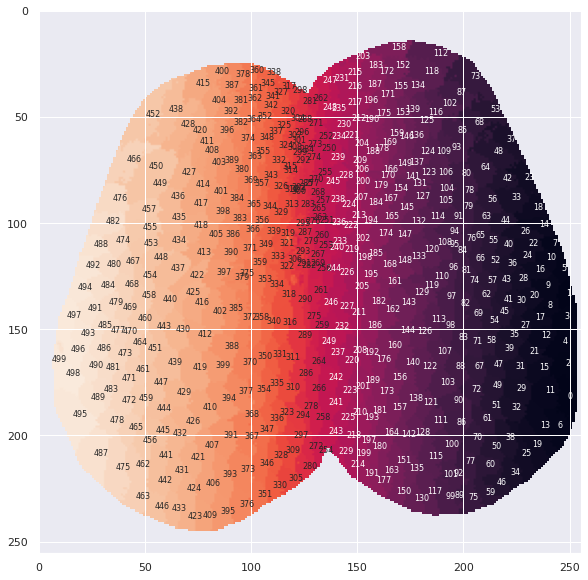

In [71]:
plt.figure(figsize=(10,10))
plt.imshow(IDX_sorted)#,cmap='coolwarm')
#plt.clim([-50,200])
for i in range(node_coords.shape[0]):
    if i<250:
        plt.text(node_coords[i,1], node_coords[i,0], str(i),color='w',fontsize=8)
    else:
        plt.text(node_coords[i,1], node_coords[i,0], str(i),fontsize=8)